# Lecture 12S companion: state space models in a few lines of NumPy

This notebook accompanies the study guide *Chapter 12S: State Space Models*. Each section names the guide section it belongs to, so you can read the explanation first and then experiment. Run the cells from top to bottom. Every section asks you to predict the result before running it; write your guess down, then check it. The notebook needs only NumPy and matplotlib and runs in a few seconds on a laptop.

Symbols, as in the guide: x is the input, h the state (the model's memory), y the output, a the memory factor (how much of the state survives one step), L the number of tokens, N the number of numbers in the state, and Δ the step size (how much time one token lasts).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (8, 3)

## 1. A memory of one number

*Study guide, Section 12S.2.*

The smallest memory is a single number h, updated with every input x_t:

h_t = a · h_{t−1} + (1 − a) · x_t

Read it term by term: a · h_{t−1} is the part of the old memory that survives one step, and (1 − a) · x_t is the new input, written with the remaining weight. This is the moving average used by momentum and Adam. An input from k steps ago ends up with weight (1 − a) · a^k, so it fades geometrically. The half-life, the number of steps after which half of an input is left, is ln 2 / (−ln a), about 0.69 / (1 − a) when a is close to 1.

Below, two memories read the same noisy signal, which jumps from 1 to 3 at step 40. Then we feed a single pulse and measure how long it takes to fall to one half.

**Predict first:** which memory reacts faster to the jump, a = 0.5 or a = 0.9? What half-life do you expect for a = 0.9?

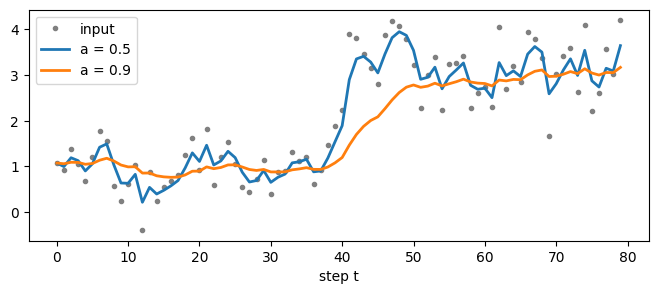

a = 0.9: half-life measured 7 steps, formula 6.6, approximation 6.9
a = 0.99: half-life measured 69 steps, formula 69.0, approximation 69.0


In [2]:
T = 80
t = np.arange(T)
signal = np.where(t < 40, 1.0, 3.0) + 0.6 * rng.normal(size=T)

def moving_average(x, a):
    h, out = x[0], []
    for x_t in x:
        h = a * h + (1 - a) * x_t        # keep a share a of the memory, write the rest
        out.append(h)
    return np.array(out)

plt.plot(t, signal, ".", color="gray", label="input")
for a in [0.5, 0.9]:
    plt.plot(t, moving_average(signal, a), lw=2, label=f"a = {a}")
plt.xlabel("step t"); plt.legend(); plt.show()

# Half-life: feed one pulse of size 1 and count the steps until half of it is left
for a in [0.9, 0.99]:
    pulse = np.zeros(2000); pulse[0] = 1.0
    h = moving_average(pulse, a)             # the state starts at 1 and then only fades
    steps = np.argmax(h < 0.5)
    print(f"a = {a}: half-life measured {steps} steps, formula {np.log(2) / -np.log(a):.1f}, approximation {0.69 / (1 - a):.1f}")

**What to notice:** with a = 0.5 the memory reacts within a few steps but follows the noise; with a = 0.9 it is smooth but needs about 20 steps to reach the new level. One number cannot be both quick and smooth. The measured half-lives match the formula (the count is the first whole step below one half), and moving a ten times closer to 1 makes the memory ten times longer.

**Try this:** set a = 0.999. How long is the half-life now? Why would a deep network need memory factors this close to 1?

## 2. Two ways to compute

*Study guide, Sections 12S.2 and 12S.3.*

Now give the state N = 4 numbers, each with its own memory factor λ_n (a diagonal state matrix), its own write strength B_n and its own read strength C_n. The output is y_t = Σ_n C_n h_{t,n}.

There are two ways to compute the outputs. The **recurrence** updates the state one token at a time: h_{t,n} = λ_n h_{t−1,n} + B_n x_t. The **convolution** writes every output as a weighted sum of all past inputs, y_t = Σ_k K_k x_{t−k}, with the kernel K_k = Σ_n C_n λ_n^k B_n: an input from k steps ago is written with B_n, fades by λ_n at each of the k steps, and is read with C_n. Because the weights depend only on k, the whole output is one convolution, which can be computed for all tokens at once.

**Predict first:** how different will the two outputs be?

max |difference|: 1.0658141036401503e-14


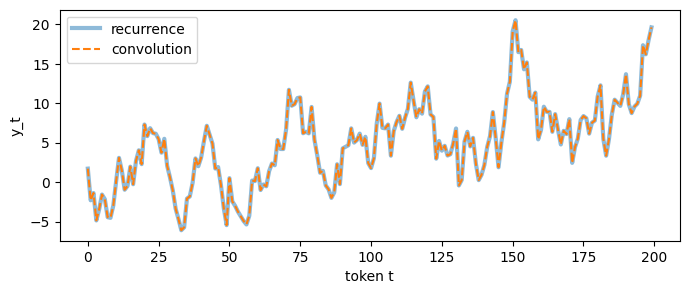

In [3]:
N, L = 4, 200
lam = np.array([0.5, 0.8, 0.95, 0.99])   # four memory factors: short to long memory
B = rng.normal(size=N)                   # write strengths
C = rng.normal(size=N)                   # read strengths
x = rng.normal(size=L)                   # one input channel, L tokens

# Way 1: recurrence, one token at a time
h, y_rec = np.zeros(N), []
for x_t in x:
    h = lam * h + B * x_t
    y_rec.append(C @ h)
y_rec = np.array(y_rec)

# Way 2: convolution with the kernel K[k] = sum_n C_n * lam_n**k * B_n
K = np.array([C @ (lam**k * B) for k in range(L)])
y_conv = np.convolve(x, K)[:L]           # keep the causal part

print("max |difference|:", np.abs(y_rec - y_conv).max())
plt.plot(y_rec, label="recurrence", lw=3, alpha=0.5)
plt.plot(y_conv, "--", label="convolution")
plt.xlabel("token t"); plt.ylabel("y_t"); plt.legend(); plt.show()

**What to notice:** the two outputs agree up to floating-point rounding (about 1e−15). The recurrence is the natural way to generate one token at a time with constant memory; the convolution sees the whole sequence at once, so it is the natural way to train in parallel. The kernel is as long as the sequence, yet it is built from only 3N = 12 numbers.

**Try this:** plot K. Which of the four memory factors dominates the kernel after 20 steps? After 100?

## 3. Step size and memory length

*Study guide, Section 12S.4.*

S4 and Mamba write each state entry as changing continuously in time, h′(τ) = A h(τ) + B x(τ), with A negative, and learn a step size Δ: how much time one token lasts. The zero-order hold turns this into the per-token update with memory factor Ā = exp(Δ A) and write strength B̄ = (exp(Δ A) − 1) / A · B, which is about Δ B for a short step. The half-life in tokens is ln 2 / (|A| Δ).

Below, one fixed set of continuous parameters is discretized with three step sizes.

**Predict first:** as Δ gets smaller, does the kernel get shorter or longer?

Δ = 0.1: half-lives in tokens [13.1  3.3 22.3 29.1]
Δ = 0.03: half-lives in tokens [43.8 11.1 74.5 97. ]
Δ = 0.01: half-lives in tokens [131.5  33.3 223.5 290.9]


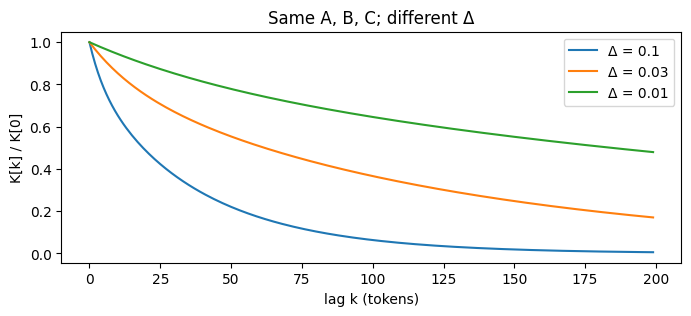

In [4]:
A = -np.exp(rng.normal(size=N))          # continuous rates, all negative (stable)

def discretize(A, B, dt):
    """Zero-order hold for a diagonal A, entry by entry."""
    A_bar = np.exp(dt * A)               # fraction of each entry kept per token
    B_bar = (A_bar - 1) / A * B          # how much one token writes
    return A_bar, B_bar

for dt in [0.1, 0.03, 0.01]:
    A_bar, B_bar = discretize(A, B, dt)
    K = np.array([C @ (A_bar**k * B_bar) for k in range(L)])
    plt.plot(K / K[0], label=f"Δ = {dt}")  # scaled so every kernel starts at 1
    print(f"Δ = {dt}: half-lives in tokens", np.round(np.log(2) / (-A * dt), 1))
plt.xlabel("lag k (tokens)"); plt.ylabel("K[k] / K[0]")
plt.title("Same A, B, C; different Δ"); plt.legend(); plt.show()

**What to notice:** a smaller Δ means each token covers less time, so Ā = exp(ΔA) is closer to 1 and the state forgets more slowly per token. The kernel stretches out and every half-life grows in proportion to 1/Δ: the same model now has a longer memory measured in tokens. This is why S4 could be run on audio sampled at a different rate just by changing Δ, and why Mamba can use a token-dependent Δ as a gate.

## 4. Activity: sequential and parallel scan

*Study guide, Section 12S.7.*

Mamba computes Δ from each token (selection), so the kernel is different at every position and the convolution is gone. Each state entry still follows h_t = a_t h_{t−1} + b_t, where a_t is the fraction kept at step t and b_t what step t writes. All a_t and b_t are known once the tokens are known. One step, multiply by a_t and add b_t, is described by the pair (a_t, b_t), and two steps in a row combine into one pair:

(a₁, b₁) ⊕ (a₂, b₂) = (a₁a₂, a₂b₁ + b₂)

The first entry is the fraction of the starting state that survives both steps; the second is what both steps write together. Because the grouping of the combinations does not matter, all L states can be computed in about log₂ L parallel rounds instead of L sequential steps.

Here A = −1, a_t = exp(−Δ_t), b_t = (1 − a_t) x_t (the zero-order hold with B = 1), and the step size Δ_t = softplus(3 x_t) depends on the token. Softplus, log(1 + e^z), keeps it positive.

**Predict first:** will the parallel scan give exactly the same states as the loop? How many rounds does it need for L = 16?

In [5]:
def seq_scan(a, b):            # h_t = a_t * h_{t-1} + b_t, with h_0 = 0
    h, out = 0.0, []
    for a_t, b_t in zip(a, b):
        h = a_t * h + b_t
        out.append(h)
    return np.array(out)

def par_scan(a, b):            # Hillis-Steele scan: log2(L) rounds, each fully parallel
    a, b, k = a.copy(), b.copy(), 1
    while k < len(a):          # combine each element with the one k steps back:
        b[k:] = a[k:] * b[:-k] + b[k:]   # (a1,b1) o (a2,b2) = (a1*a2, a2*b1 + b2)
        a[k:] = a[k:] * a[:-k]
        k *= 2
    return b

L = 16
x = rng.normal(size=L)
delta = np.log1p(np.exp(3 * x))          # selective step size: softplus(Linear(x_t))
a = np.exp(-delta)                       # A = -1  ->  a_t = exp(delta_t * A)
b = (1 - a) * x                          # ZOH with B = 1  ->  b_t = (1 - a_t) x_t
print("same states:", np.allclose(seq_scan(a, b), par_scan(a, b)))
print("rounds:", int(np.ceil(np.log2(L))), "instead of", L, "sequential steps")

same states: True
rounds: 4 instead of 16 sequential steps


Optional: the blocked scan. GPUs split a long sequence into chunks that fit in fast memory, scan each chunk independently, pass a small summary between chunks, and then fix up each chunk with the state it should have started from.

In [6]:
def blocked_scan(a, b, K):     # chunks are independent, so they can run in parallel
    a, b = a.reshape(-1, K), b.reshape(-1, K)
    h = np.stack([seq_scan(ai, bi) for ai, bi in zip(a, b)])  # 1) scan each block from h=0
    carry = seq_scan(np.prod(a, axis=1), h[:, -1])             # 2) scan over block summaries
    h0 = np.concatenate([[0.0], carry[:-1]])                   #    state entering each block
    return (h + np.cumprod(a, axis=1) * h0[:, None]).ravel()   # 3) fix up with carried state

L = 64
x = rng.normal(size=L)
a = np.exp(-np.log1p(np.exp(3 * x)))
b = (1 - a) * x
print("blocked scan matches:", np.allclose(seq_scan(a, b), blocked_scan(a, b, K=8)))

blocked scan matches: True


**What to notice:** every line inside `par_scan` is one vectorized operation over the whole sequence, which a GPU executes as a single parallel step. The trick works because a_t depends on the input x_t but never on the state h_{t−1}.

**Try this:** change the update in `seq_scan` to `h = np.tanh(a_t * h + b_t)`, as in a classic RNN. Can you write an operator ⊕ that combines two such steps into one step of the same form? (You cannot, and that is exactly why nonlinear RNNs must be trained one step at a time.)

## 5. The state is an associative memory

*Study guide, Section 12S.8.*

Linear attention stores key-value pairs in one d × d matrix **S** by adding outer products, **S** += **v** **k**ᵀ (write the value v under the key k), and reads a value back with **S** **k**. If the keys overlap, every read also returns a bit of every other stored value: crosstalk. The delta rule first reads what the memory returns for the new key and writes only the error, **S** += (**v** − **S** **k**) **k**ᵀ, so it overwrites what the memory currently returns for that key. Here keys and values are random unit vectors in d = 16 dimensions, and n is the number of stored pairs.

**Predict first:** at n = 64 stored pairs, which method recalls the first pairs written better? Which recalls the last ones better?

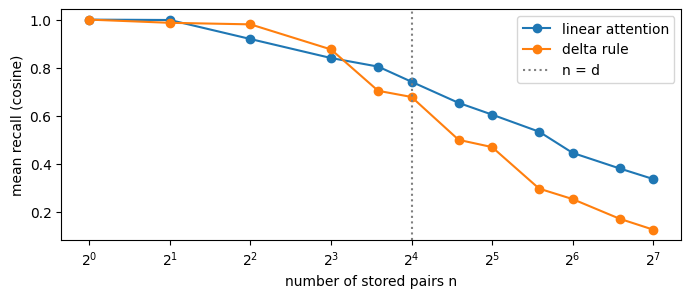

linear  first 8 pairs: +0.57   last 8 pairs: +0.46
delta   first 8 pairs: -0.08   last 8 pairs: +0.87


In [7]:
d = 16

def unit(n):
    v = rng.normal(size=(n, d))
    return v / np.linalg.norm(v, axis=1, keepdims=True)

def store(keys, vals, rule):
    S = np.zeros((d, d))
    for k, v in zip(keys, vals):
        S += np.outer(v if rule == "linear" else v - S @ k, k)
    return S

def recall(S, keys, vals):            # cosine similarity between S k_i and v_i, per pair
    out = keys @ S.T
    return np.sum(out * vals, axis=1) / (np.linalg.norm(out, axis=1) + 1e-12)

sizes = [1, 2, 4, 8, 12, 16, 24, 32, 48, 64, 96, 128]
for rule in ["linear", "delta"]:
    means = []
    for n in sizes:
        keys, vals = unit(n), unit(n)
        means.append(recall(store(keys, vals, rule), keys, vals).mean())
    plt.plot(sizes, means, "o-", label="linear attention" if rule == "linear" else "delta rule")
plt.axvline(d, color="gray", ls=":", label="n = d")
plt.xscale("log", base=2); plt.xlabel("number of stored pairs n"); plt.ylabel("mean recall (cosine)")
plt.legend(); plt.show()

keys, vals = unit(64), unit(64)
for rule in ["linear", "delta"]:
    r = recall(store(keys, vals, rule), keys, vals)
    print(f"{rule:6s}  first 8 pairs: {r[:8].mean():+.2f}   last 8 pairs: {r[-8:].mean():+.2f}")

**What to notice:** at most d keys can be at right angles to each other in d dimensions, so a d × d matrix can hold about d pairs without interference. Up to about n = d both methods recall well; beyond that, linear attention blurs every pair a little (crosstalk from all the others), while the delta rule recalls the most recent pairs well (the very last one exactly) and has largely overwritten the oldest ones. A fixed-size state must forget something; the update rule decides what. This is the motivation for gated delta rules and for hybrids that keep a few full attention layers.

## 6. Optional, going further: two algorithms, one function

*Study guide, Section 12S.8, "Every sequence layer is a matrix". This section goes beyond the lecture.*

Mamba-2 shrinks the whole state by one number a_t per token. Then the layer can be computed in two ways that give the same output. In the recurrent mode the state is an N × P matrix, updated as **H**_t = a_t **H**_{t−1} + **b**_t **x**_tᵀ and read as **y**_t = **H**_tᵀ **c**_t. In the attention-like mode we build an L × L matrix **M** whose entry (t, s) is the weight of input s in output t: the dot product of the read vector **c**_t with the write vector **b**_s, times the product of the decays in between, a_t a_{t−1} ⋯ a_{s+1}, and zero above the diagonal. Read **C** as the queries, **B** as the keys and **X** as the values.

**Predict first:** will the two modes agree? What do you expect if every a_t = 1?

In [8]:
L, N, P = 8, 4, 3
a = rng.uniform(0.5, 1.0, size=L)          # one scalar decay per token
B, C = rng.normal(size=(L, N)), rng.normal(size=(L, N))
X = rng.normal(size=(L, P))

def recurrent_mode(a, B, C, X):
    H, Y = np.zeros((B.shape[1], X.shape[1])), []
    for t in range(len(a)):
        H = a[t] * H + np.outer(B[t], X[t])   # state is N x P
        Y.append(C[t] @ H)
    return np.array(Y)

def decay_mask(a):
    lc = np.cumsum(np.log(a))                 # stable: L[t, s] = exp(lc[t] - lc[s])
    return np.tril(np.exp(lc[:, None] - lc[None, :]))

def attention_mode(a, B, C, X):
    M = decay_mask(a) * (C @ B.T)             # L x L, like a masked attention matrix
    return M @ X

print("same output:", np.allclose(recurrent_mode(a, B, C, X), attention_mode(a, B, C, X)))

same output: True


In [9]:
# Extension 1: all decays equal to 1 -> the mask is the plain causal mask (causal linear attention)
ones = np.ones(L)
print("mask with a = 1:\n", decay_mask(ones).astype(int))
print("still equal:", np.allclose(recurrent_mode(ones, B, C, X), attention_mode(ones, B, C, X)))

# Extension 2: a block of M strictly below the diagonal has rank at most N
L2 = 24
a2 = rng.uniform(0.8, 1.0, size=L2)
B2, C2 = rng.normal(size=(L2, N)), rng.normal(size=(L2, N))
M = decay_mask(a2) * (C2 @ B2.T)
print("singular values of M[12:, :12]:", np.round(np.linalg.svd(M[12:, :12], compute_uv=False), 4))

mask with a = 1:
 [[1 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 0]
 [1 1 1 0 0 0 0 0]
 [1 1 1 1 0 0 0 0]
 [1 1 1 1 1 0 0 0]
 [1 1 1 1 1 1 0 0]
 [1 1 1 1 1 1 1 0]
 [1 1 1 1 1 1 1 1]]
still equal: True
singular values of M[12:, :12]: [7.0219 4.6643 3.025  2.0393 0.     0.     0.     0.     0.     0.
 0.     0.    ]


**What to notice:** the recurrent and attention-like modes compute the same function. The recurrence costs O(L) and is ideal for generating text token by token; the matrix form costs O(L²) but uses matrix multiplications, which GPUs run very fast, so Mamba-2 uses it inside short chunks. With every a_t = 1 the mask becomes the causal mask of linear attention. Only N = 4 singular values of the off-diagonal block are nonzero: everything the past passes to the future goes through the N-dimensional state, which is what makes **M** cheap to apply.